In [6]:
import dspy
import torch
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np

from agfn.modules import create_agfn, ExpertType, ElicitationStrategy
from agfn.gym import LogReward

from agfn.commons import topk_numpy

dspy.configure_cache(
    enable_disk_cache=False, enable_memory_cache=False
)
torch.manual_seed(42)

In [7]:
device = "cpu"
assert device == "cpu", "Currently, only CPU is supported"

In [8]:
data_path = "data/chain4_dat01.csv"
# data_path = "data/collfork_dat01.csv"
data = pd.read_csv(data_path)
data = torch.tensor(data.values, dtype=torch.get_default_dtype(), device=device)

def create_adj(data_path: str, num_nodes: int) -> torch.Tensor:
    match data_path:
        case "data/chain4_dat01.csv":
            # a -> b -> c -> d
            adj = torch.zeros(num_nodes, num_nodes)
            adj[0, 1] = 1
            adj[1, 2] = 1
            adj[2, 3] = 1
        case "data/collfork_dat01.csv":
            # vars = [W, X, Y, Z]
            # X -> Z <-> Y <- W
            # X <-> W -> Z
            adj = torch.zeros(num_nodes, num_nodes)
            # W (0), X (1), Y (2), Z (3)
            # X -> Z: 1 -> 3
            adj[1, 3] = 1
            # Z <-> Y: 3 <-> 2
            adj[3, 2] = 1
            adj[2, 3] = 1
            # Y <- W: 2 <- 0
            adj[0, 2] = 1
            # X <-> W: 1 <-> 0
            adj[1, 0] = 1
            adj[0, 1] = 1
            # W -> Z: 0 -> 3
            adj[0, 3] = 1
    return adj

num_nodes = data.shape[1]
adj = create_adj(data_path, num_nodes)

In [9]:
log_reward = LogReward(data)
agfn = create_agfn(
    ExpertType.LLM_WIKIPEDIA, 
    ElicitationStrategy.LARGEST_ENTROPY, 
    log_reward, 
    expert_with_confidence=True,
    expert_kwargs={"adj": adj, "num_nodes": num_nodes, "llm_name": "ollama_chat/gemma3:4b", "max_depth": 2, "ensemble_size": 5}, # llama3.2:1b, deepseek-r1:1.5b 
    gflownet_kwargs={"hidden_dim": 128, "num_layers": 2, "criterion": "tb"}
)

In [10]:
agfn.temperature_warmup()
log_z_values = agfn.train(num_epochs=500)

100%|██████████| 500/500 [00:31<00:00, 16.10it/s, loss=0.102] 


In [11]:
agfn.eval_mode()
agfn.reset_queries()
agfn.feedback_loop()

 17%|█▋        | 1/6 [04:28<22:23, 268.64s/it]2025/08/19 08:43:47 WARNING dspy.adapters.json_adapter: Failed to use structured output format, falling back to JSON mode.
2025/08/19 08:44:06 WARNING dspy.adapters.json_adapter: Failed to use structured output format, falling back to JSON mode.
 33%|███▎      | 2/6 [09:23<18:56, 284.08s/it]2025/08/19 08:48:14 WARNING dspy.adapters.json_adapter: Failed to use structured output format, falling back to JSON mode.
2025/08/19 08:48:32 WARNING dspy.adapters.json_adapter: Failed to use structured output format, falling back to JSON mode.
2025/08/19 08:48:51 WARNING dspy.adapters.json_adapter: Failed to use structured output format, falling back to JSON mode.
2025/08/19 08:49:10 WARNING dspy.adapters.json_adapter: Failed to use structured output format, falling back to JSON mode.
2025/08/19 08:49:28 WARNING dspy.adapters.json_adapter: Failed to use structured output format, falling back to JSON mode.


Error parsing the response from the LLM. Returning the tentative relationship. Error: Both structured output format and JSON mode failed. Please choose a model that supports `response_format` argument. Original error: Node 0 directly causes node 3 is not a valid name or value for the enum EdgeType
Error parsing the response from the LLM. Returning the tentative relationship. Error: Both structured output format and JSON mode failed. Please choose a model that supports `response_format` argument. Original error: DIRECT is not a valid name or value for the enum EdgeType
Error parsing the response from the LLM. Returning the tentative relationship. Error: Both structured output format and JSON mode failed. Please choose a model that supports `response_format` argument. Original error: indirect_confluence is not a valid name or value for the enum EdgeType


2025/08/19 08:51:16 WARNING dspy.adapters.json_adapter: Failed to use structured output format, falling back to JSON mode.
2025/08/19 08:51:32 WARNING dspy.adapters.json_adapter: Failed to use structured output format, falling back to JSON mode.
 50%|█████     | 3/6 [15:01<15:26, 308.67s/it]

Error parsing the response from the LLM. Returning the tentative relationship. Error: Both structured output format and JSON mode failed. Please choose a model that supports `response_format` argument. Original error: Latent Confounding is not a valid name or value for the enum EdgeType


2025/08/19 08:54:08 WARNING dspy.adapters.json_adapter: Failed to use structured output format, falling back to JSON mode.
2025/08/19 08:54:28 WARNING dspy.adapters.json_adapter: Failed to use structured output format, falling back to JSON mode.
2025/08/19 08:54:48 WARNING dspy.adapters.json_adapter: Failed to use structured output format, falling back to JSON mode.
2025/08/19 08:55:07 WARNING dspy.adapters.json_adapter: Failed to use structured output format, falling back to JSON mode.
2025/08/19 08:55:25 WARNING dspy.adapters.json_adapter: Failed to use structured output format, falling back to JSON mode.


Error parsing the response from the LLM. Returning the tentative relationship. Error: Both structured output format and JSON mode failed. Please choose a model that supports `response_format` argument. Original error: causes is not a valid name or value for the enum EdgeType
Error parsing the response from the LLM. Returning the tentative relationship. Error: Both structured output format and JSON mode failed. Please choose a model that supports `response_format` argument. Original error: DIRECT is not a valid name or value for the enum EdgeType
Error parsing the response from the LLM. Returning the tentative relationship. Error: Both structured output format and JSON mode failed. Please choose a model that supports `response_format` argument. Original error: direct is not a valid name or value for the enum EdgeType
Error parsing the response from the LLM. Returning the tentative relationship. Error: Adapter JSONAdapter failed to parse the LM response. 

LM Response: {} 

Expected to f

... (2 outputs left out)

2025/08/19 09:00:00 WARNING dspy.adapters.json_adapter: Failed to use structured output format, falling back to JSON mode.
 83%|████████▎ | 5/6 [24:26<04:52, 292.20s/it]2025/08/19 09:03:23 WARNING dspy.adapters.json_adapter: Failed to use structured output format, falling back to JSON mode.
2025/08/19 09:03:40 WARNING dspy.adapters.json_adapter: Failed to use structured output format, falling back to JSON mode.
2025/08/19 09:03:57 WARNING dspy.adapters.json_adapter: Failed to use structured output format, falling back to JSON mode.
2025/08/19 09:04:15 WARNING dspy.adapters.json_adapter: Failed to use structured output format, falling back to JSON mode.
2025/08/19 09:04:31 WARNING dspy.adapters.json_adapter: Failed to use structured output format, falling back to JSON mode.


Error parsing the response from the LLM. Returning the tentative relationship. Error: Adapter JSONAdapter failed to parse the LM response. 

LM Response: {} 

Expected to find output fields in the LM response: [reasoning, relationship, judgement, confidence] 

Actual output fields parsed from the LM response: [] 


Error parsing the response from the LLM. Returning the tentative relationship. Error: Adapter JSONAdapter failed to parse the LM response. 

LM Response: {} 

Expected to find output fields in the LM response: [reasoning, relationship, judgement, confidence] 

Actual output fields parsed from the LM response: [] 


Error parsing the response from the LLM. Returning the tentative relationship. Error: Adapter JSONAdapter failed to parse the LM response. 

LM Response: {} 

Expected to find output fields in the LM response: [reasoning, relationship, judgement, confidence] 

Actual output fields parsed from the LM response: [] 


Error parsing the response from the LLM. Returnin

100%|██████████| 6/6 [28:21<00:00, 283.61s/it]

Error parsing the response from the LLM. Returning the tentative relationship. Error: Adapter JSONAdapter failed to parse the LM response. 

LM Response: {} 

Expected to find output fields in the LM response: [reasoning, relationship, judgement, confidence] 

Actual output fields parsed from the LM response: [] 




In [12]:
graphs, log_scores = agfn.sample(num_samples=100, batch_size=32, progress_bar=True, log_reward_coef=0.1)

100%|██████████| 100/100 [00:01<00:00, 84.15it/s]


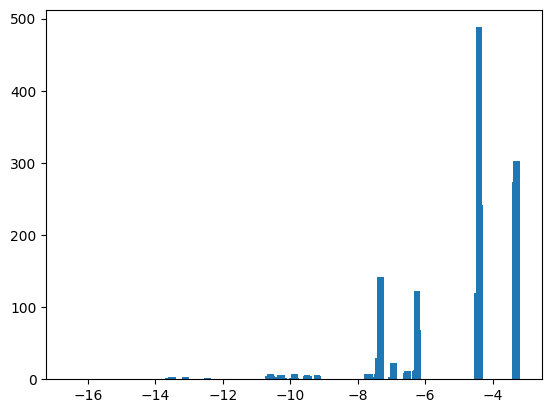

In [13]:
from collections import Counter

scores_to_string = [log_score for log_score in  log_scores.tolist()]

scores_counter = Counter(scores_to_string)

keys = list(scores_counter.keys())
values = [scores_counter[key] for key in keys]
plt.bar(keys, values, width=0.2)
# plt.xlim(max(keys) * 0.4, max(keys) * 1.1)
plt.show()

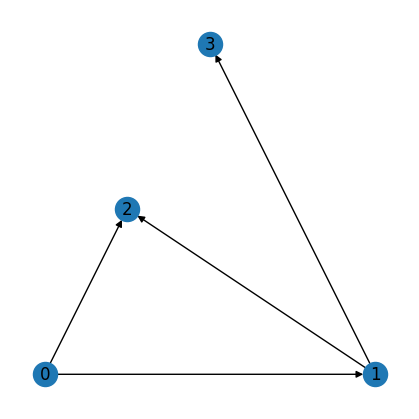

In [14]:
largest_reward_samples = topk_numpy(log_scores, k=100)

adjacency_matrices = np.unique(graphs[largest_reward_samples], axis=0)

for i in range(len(adjacency_matrices)):
    g = nx.from_numpy_array(adjacency_matrices[i], create_using=nx.MultiDiGraph)
    layout = nx.planar_layout(g)
    plt.figure(figsize=(4, 4))
    nx.draw(g, pos=layout, with_labels=True)
    plt.show()

## Reset the queries and compute the evolving SHD

  0%|          | 0/1 [00:00<?, ?it/s]2025/08/17 11:50:16 WARNING dspy.adapters.json_adapter: Failed to use structured output format, falling back to JSON mode.
2025/08/17 11:50:19 WARNING dspy.adapters.json_adapter: Failed to use structured output format, falling back to JSON mode.
2025/08/17 11:50:21 WARNING dspy.adapters.json_adapter: Failed to use structured output format, falling back to JSON mode.
2025/08/17 11:50:24 WARNING dspy.adapters.json_adapter: Failed to use structured output format, falling back to JSON mode.
2025/08/17 11:50:26 WARNING dspy.adapters.json_adapter: Failed to use structured output format, falling back to JSON mode.
2025/08/17 11:50:28 WARNING dspy.adapters.json_adapter: Failed to use structured output format, falling back to JSON mode.
2025/08/17 11:50:31 WARNING dspy.adapters.json_adapter: Failed to use structured output format, falling back to JSON mode.
2025/08/17 11:50:35 WARNING dspy.adapters.json_adapter: Failed to use structured output format, fallin

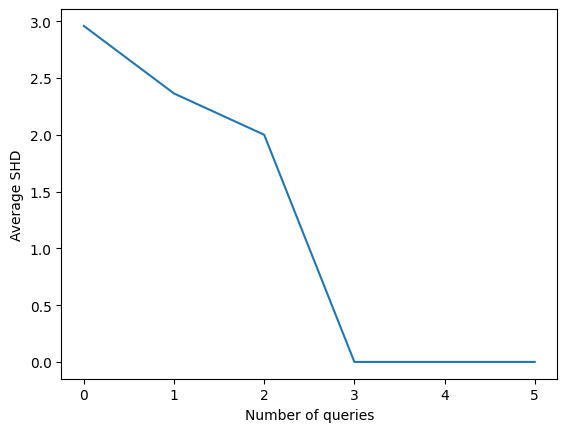

In [ ]:
agfn.reset_queries()

shd_values = []

for i in range(agfn.expert.num_node_pairs):
    agfn.feedback_loop(num_feedbacks=1)

    samples, log_scores = agfn.sample(num_samples=100, batch_size=32, progress_bar=True, log_reward_coef=1/(i + 1))

    largest_reward_samples = topk_numpy(log_scores, k=100)

    adjacency_matrices = np.unique(samples[largest_reward_samples], axis=0)

    avg_shd = np.mean(
        [np.abs(amat - adj.cpu().numpy()).sum() for amat in adjacency_matrices]
    )

    shd_values.append(avg_shd)

plt.plot(shd_values)
plt.ylabel("Average SHD")
plt.xlabel("Number of queries")
plt.show()